# 2회차 스터디
 - 1회차 복습
   - EDA, 시각화
   - 지도학습

In [2]:
# 기존 라이브러리 - 복붙하세요. ctrl + c, ctrl + v
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
# plt.rcParams['font.family'] = 'AppleSDGothicNeo'   # 한글 폰트 설정: Mac
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

# 복습

In [ ]:
# 데이터 불러오기
df = pd.read_csv('iris.csv')
df


In [6]:
# 데이터프레임 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [8]:
# 데이터프레임 기본적 기술통계
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
sns.histplot(data=df, x='sepal_length', hue='species')

In [ ]:
corr = df.iloc[:, :-1].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

In [ ]:
sns.pairplot(df, hue='species', markers=['o', 's', 'D'])

# 머신러닝
 - 딥러닝 vs 머신러닝
 - 지도학습 vs 비지도학습
 - 학습 알고리즘(모델)
 - 하이퍼 파라메터  vs (그냥)파라메터
 - 데이터와 라벨

In [ ]:
# 모델 훈련을 위한 데이터 준비
from sklearn.model_selection import train_test_split

# 피처와 라벨 분리
X = df.drop(columns = 'species')   # 피처         - 설명변수, 독립변수  (꽃잎 길이, 꽃잎 너비, 꽃받침 길이, 꽃받침 너비)
y = df['species']                  # 라벨, 타겟    - 목표변수, 종속변수  (종)

# 데이터셋 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


In [ ]:
# 어떻게 나뉘었는지 확인
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((105, 4), (45, 4), (105,), (45,))

# 모델 학습

In [ ]:
# 의사결정나무 decision tree 모델 학습
from sklearn.tree import DecisionTreeClassifier

# 모델 불러오기
model = DecisionTreeClassifier(random_state=42)  # 난수 시드 고정은 선택사항

# 모델 학습
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)
y_pred


array(['virginica', 'versicolor', 'virginica', 'virginica', 'virginica',
       'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'setosa', 'virginica', 'virginica', 'setosa',
       'virginica', 'versicolor', 'setosa', 'setosa', 'setosa',
       'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa',
       'virginica', 'virginica', 'virginica', 'setosa', 'virginica',
       'setosa', 'setosa', 'setosa', 'setosa', 'virginica', 'versicolor',
       'setosa', 'virginica', 'virginica', 'versicolor'], dtype=object)

In [68]:
# 모델 평가
## 정확도 계산 accuracy
acc = (y_pred == y_test).sum() / len(y_test)
print(f'정확도: {acc*100:.3f}%')


정확도: 93.333%


In [69]:
# 평가 라이브러리 활용하여 정확도 계산
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test, y_pred)
print(f'정확도: {acc*100:.3f}%')


정확도: 93.333%


In [96]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
56,6.3,3.3,4.7,1.6,versicolor,virginica,False
85,6.0,3.4,4.5,1.6,versicolor,virginica,False
77,6.7,3.0,5.0,1.7,versicolor,virginica,False


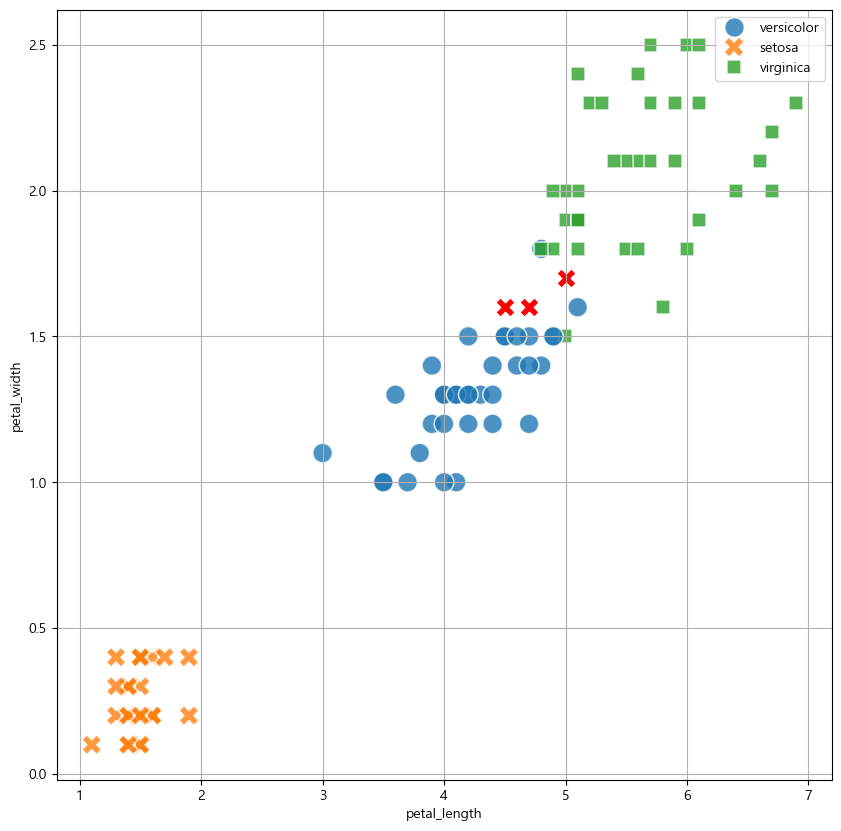

In [ ]:
# 뭐가 틀렸는지 시각화
plt.figure(figsize=(10, 10))

sns.scatterplot(data=X_train, x='petal_length', y='petal_width', hue=y_train, alpha=0.8, style=y_train, s=200)
# sns.scatterplot(data=result, x='petal_length', y='petal_width', hue='y_test', style='y_test', s=200)
wrong = result[result['정답'] == False]
sns.scatterplot(data=wrong, x='petal_length', y='petal_width', marker='X', color='red', s=200)
plt.grid(True)

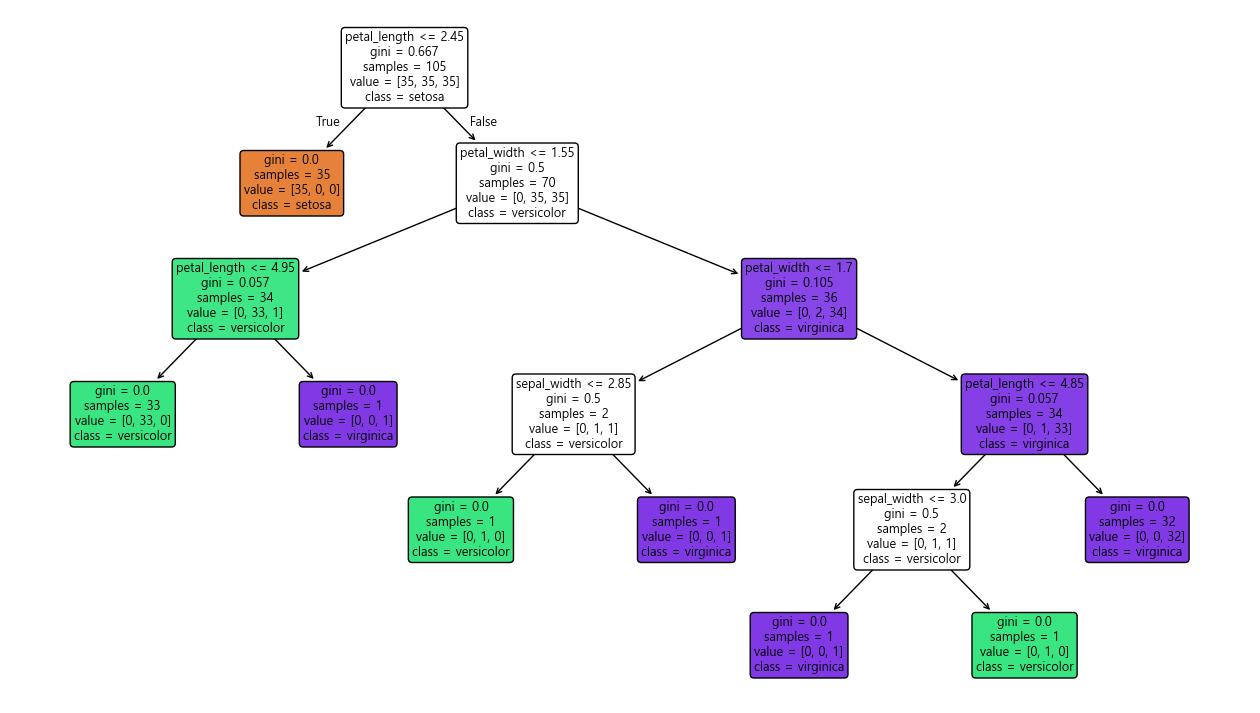

In [75]:
# 트리 그래프
from sklearn.tree import plot_tree
plt.figure(figsize=(16, 9))
_ = plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, fontsize=9)

In [ ]:
# 불순도 계산


0.6666666666666667

- 트리 읽는 법
  - 노드 vs 엣지
  - 루트 노드
  - 리프 노드
  - 깊이
  - 분할
  - 지니 불순도
    - 1 - ((35/105)**2 + (35/105)**2 + (35/105)**2)

In [ ]:
# 모델을 바꿔보자
from sklearn.tree import DecisionTreeClassifier

# 모델 불러오기
model = DecisionTreeClassifier(
    random_state=42,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1
)
# 모델 학습
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)
y_pred


In [121]:
# 모델 평가
## 정확도 계산 accuracy
acc = (y_pred == y_test).sum() / len(y_test)
print(f'정확도: {acc*100:.3f}%')


정확도: 97.778%


In [122]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
77,6.7,3.0,5.0,1.7,versicolor,virginica,False


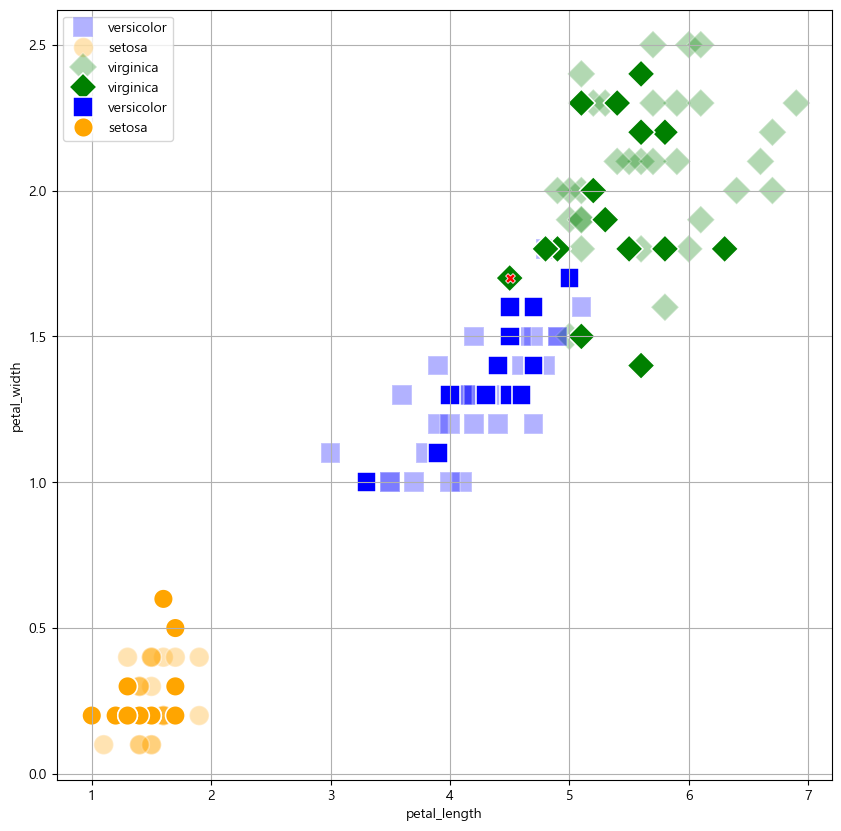

In [153]:
# 뭐가 틀렸는지 시각화
plt.figure(figsize=(10, 10))
colors = {
    'setosa': 'orange',
    'versicolor': 'blue',
    'virginica': 'green'
}
marker = {
    'setosa': 'o',
    'versicolor': 's',
    'virginica': 'D'
}
sns.scatterplot(data=X_train, x='petal_length', y='petal_width', hue=y_train, alpha=0.3, style=y_train, s=200, palette=colors, markers=marker)
sns.scatterplot(data=result , x='petal_length', y='petal_width', hue=y_test , alpha=1  , style=y_test , s=200, palette=colors, markers=marker)
wrong = result[result['정답'] == False]
sns.scatterplot(data=wrong, x='petal_length', y='petal_width', marker='X', color='red', s=50)
plt.grid(True)

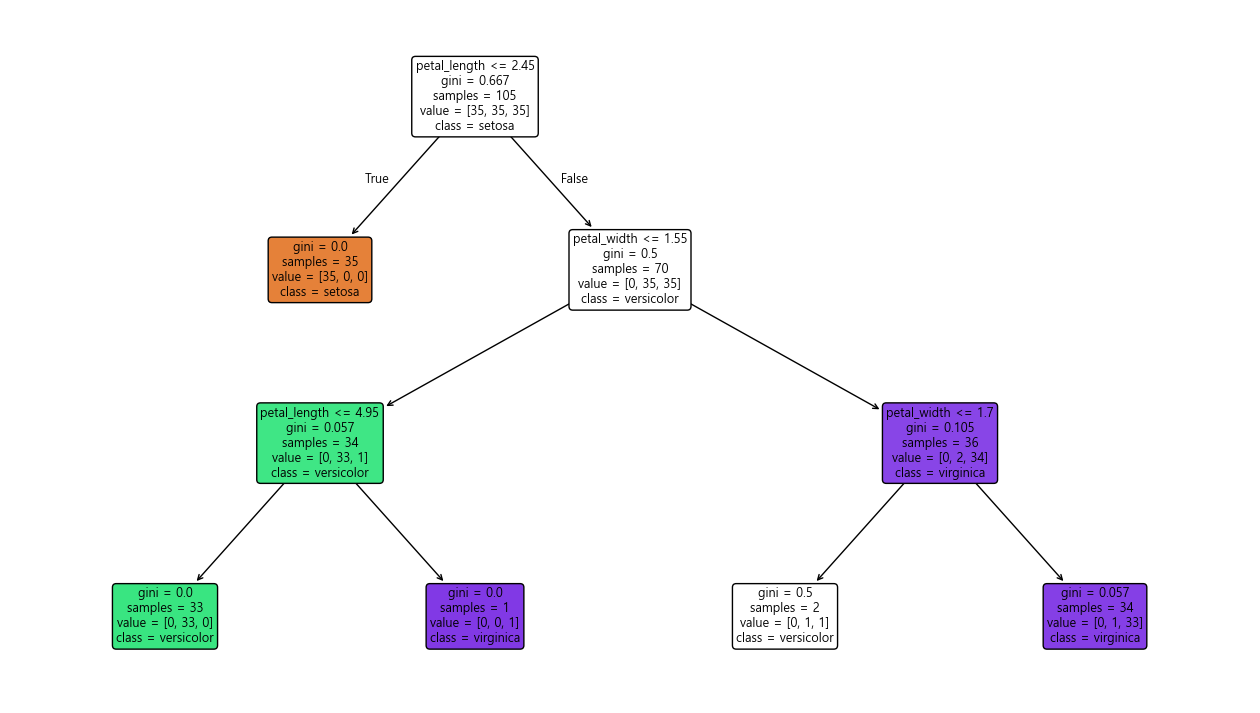

In [124]:
# 트리 그래프
from sklearn.tree import plot_tree
plt.figure(figsize=(16, 9))
_ = plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, fontsize=9)

※ 복잡한게 좋은 성능을 내는건 아니다.

# KNN 모델

In [159]:
# 데이터 전처리
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# StandardScaler를 사용하여 표준화
scaler = StandardScaler()
scaler.fit(X_train)  # 학습 데이터에 대해 fit 수행
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Q. test-set은 왜 transform만 하는가?
##   -> 데이터 누수(data leakage) 문제 발생
## 표준화는 언제 하는가?
##   -> 거리를 사용하는 알고리즘의 경우 표준화
##   -> 선형회귀, 로지스틱 회귀, SVM, KNN 등
##   -> 트리모델은 표준화 필요 낮음

In [160]:
# knn
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)


In [161]:
# 모델 평가
## 정확도 계산 accuracy
acc = (y_pred == y_test).sum() / len(y_test)
print(f'정확도: {acc*100:.3f}%')


정확도: 91.111%


In [162]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
133,6.3,2.8,5.1,1.5,virginica,versicolor,False
138,6.0,3.0,4.8,1.8,virginica,versicolor,False
134,6.1,2.6,5.6,1.4,virginica,versicolor,False
106,4.9,2.5,4.5,1.7,virginica,versicolor,False


In [ ]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
106,4.9,2.5,4.5,1.7,virginica,versicolor,False


In [ ]:
# 뭐가 틀렸는지 시각화
plt.figure(figsize=(10, 10))
colors = {
    'setosa': 'orange',
    'versicolor': 'blue',
    'virginica': 'green'
}
marker = {
    'setosa': 'o',
    'versicolor': 's',
    'virginica': 'D'
}
sns.scatterplot(data=X_train, x='petal_length', y='petal_width', hue=y_train, alpha=0.3, style=y_train, s=150, palette=colors, markers=marker)
sns.scatterplot(data=result , x='petal_length', y='petal_width', hue=y_test , alpha=1  , style=y_test , s=150, palette=colors, markers=marker)
wrong = result[result['정답'] == False]
sns.scatterplot(data=wrong, x='petal_length', y='petal_width', marker='X', color='red', s=50)
plt.grid(True)

In [ ]:
# 데이터 전처리
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# StandardScaler를 사용하여 표준화
scaler = StandardScaler()
scaler.fit(X_train)  # 학습 데이터에 대해 fit 수행
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Q. test-set은 왜 transform만 하는가?
##   -> 데이터 누수(data leakage) 문제 발생
## 표준화는 언제 하는가?
##   -> 거리를 사용하는 알고리즘의 경우 표준화
##   -> 선형회귀, 로지스틱 회귀, SVM, KNN 등
##   -> 트리모델은 표준화 필요 낮음

In [ ]:
# 스케일러 결과 확인
display(X_train.describe())
display(X_train.shape)

In [ ]:
display(pd.DataFrame(X_train_scaled, columns=X_train.columns).describe().round(5))
display(X_train_scaled.shape)
# 민맥스 정규화와 차이를 비교해보자